# Lab 2: Task 2 — Outreach Model

**Author:** Harvey Luna
**Team:** Wolfgang Klein, Sydney Bailey, Harvey Luna, Nashita Khandaker

This tab is a **confirmatory check on Task 2**, the outreach model. The team's primary
Lab 2 results for both tasks are in the
[Wolfgang Klein tab](https://lone-wolfgang.github.io/brfss2015-diabetes-eda/#Lab2/WolfgangKlein),
which searches six model families plus a stacked ensemble.

This notebook rebuilds Task 2 independently with three models and much smaller searches,
using the same data preparation, rows, splits, seed and metrics. The question it answers is
whether a simpler approach reaches the same place. It does, so the primary numbers should be
read from Wolfgang's tab and this one treated as a replication.

## 1. Task 2 and how it connects to Task 1

**Task 2 predicts who has not had a cholesterol check in the past five years** (`NoCheck`).

Task 1 finds people whose profile looks like diabetes. But the outcome in this file is a
*diagnosis*, and a diagnosis needs a doctor's visit. Lab 1 found that respondents without a
recent cholesterol check had only about 39% of the diagnoses their risk profiles predicted.
Task 2 finds the people the health system is missing, so a screening program can reach them.
A person flagged by both models is high-risk and unscreened.

## 2. Setup

In [1]:
# ---- Imports ----
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, fbeta_score, confusion_matrix)
from xgboost import XGBClassifier

# ---- Settings shared with Task 1 ----
SEED = 0
N_FOLDS = 5
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 3. Load the data

Same file and recodes as Task 1. Prediabetes and diabetes are combined into
`Diabetes_binary`, and `NoCheck` flips `CholCheck` so that 1 means no check in five years.

In [2]:
# ---- Read the file and build the two outcomes ----
raw = pd.read_csv("../data/diabetes_012_health_indicators_BRFSS2015.csv")
raw["Diabetes_binary"] = (raw["Diabetes_012"] > 0).astype(int)
raw["NoCheck"] = 1 - raw["CholCheck"]

print(f"{len(raw):,} respondents")
print(f"No cholesterol check in 5 years: {raw['NoCheck'].mean():.2%}")

253,680 respondents
No cholesterol check in 5 years: 3.73%


## 4. Variables

Task 2 starts from the same 20 base variables as Task 1, with two changes:

| Variable | Task 1 | Task 2 | Why |
|---|---|---|---|
| `AnyHealthcare`, `NoDocbcCost` | withheld | **feature** | Lacking coverage or skipping care due to cost are likely *causes* of missed screening. |
| `HighBP`, `HighChol`, `HeartDiseaseorAttack`, `Stroke` | feature | **withheld** | Each is something a doctor tells you, so it implies a visit and would give away the answer. |

`CholCheck` is the outcome itself, and `Diabetes_binary` is used to filter rows (§5).

In [3]:
# ---- Feature lists ----
BASE = ["HighBP", "HighChol", "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity",
        "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "GenHlth",
        "MentHlth", "PhysHlth", "DiffWalk", "Sex", "Age", "Education", "Income"]
TOLD = ["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]

FEATURES = [c for c in BASE if c not in TOLD] + ["Age_sq", "Income_sq"]
print(len(FEATURES), "features:", ", ".join(FEATURES))

18 features: BMI, Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, AnyHealthcare, NoDocbcCost, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income, Age_sq, Income_sq


## 5. Data preparation

These steps match Task 1:

- **BMI is capped at 70.** Values above 70 behave like data-entry codes, not measurements (Lab 1).
- **Age and Income get centered squared terms**, since both relationships curve (Lab 1).
- **Duplicate rows are kept.** Lab 1 showed they are mostly distinct healthy respondents with identical answers.

One step is specific to Task 2:

- **Only undiagnosed respondents are kept.** People with a diabetes diagnosis get regular lab
  work *because* of the diagnosis, and they are already in care, so they are not outreach targets.

In [4]:
# ---- Clean and engineer features ----
df = raw.copy()
df["BMI"] = df["BMI"].clip(upper=70)
for col in ["Age", "Income"]:
    df[f"{col}_sq"] = (df[col] - df[col].mean()) ** 2

# ---- Keep undiagnosed respondents only ----
t2 = df[df["Diabetes_binary"] == 0]
X = t2[FEATURES].astype(float)
y = t2["NoCheck"].astype(int)

### Final dataset

In [5]:
# ---- Summary of the modeling dataset ----
summary = pd.DataFrame({
    "rows": [len(y)],
    "rows removed (diagnosed)": [len(df) - len(y)],
    "features": [X.shape[1]],
    "new features": ["Age_sq, Income_sq (NoCheck is the outcome)"],
    "positives (no check)": [int(y.sum())],
    "positive %": [100 * y.mean()],
    "negatives per positive": [(1 - y.mean()) / y.mean()],
}, index=["Task 2"])
summary.T

,Task 2
rows,213703
rows removed (diagnosed),39977
features,18
new features,"Age_sq, Income_sq (NoCheck is the outcome)"
positives (no check),9167
positive %,4.2896
negatives per positive,22.3122


All features are integer-coded survey answers. Binary items stay 0/1 and the ordinal scales
(`GenHlth`, `Age`, `Education`, `Income`) keep their order, so no one-hot encoding is needed.
Features are standardized inside the logistic regression pipeline only; the tree models do not need it.

## 6. Evaluation metrics

Same metrics as Task 1, chosen for the same reason: missing someone costs more than an extra contact.

- **F2** is the final score. It weights recall four times as much as precision.
- **Average precision (AP)** is used to tune hyperparameters, because F2 depends on a threshold.
  Random guessing scores the positive rate (about 0.04 here).
- **ROC-AUC** is reported for comparison with Task 1.

Accuracy is not used. With about 1 positive per 23 respondents, flagging nobody is about 96% accurate.

## 7. Splitting the data

Same split as Task 1: **70% train / 15% validation / 15% test**, stratified on the outcome, with
the same seed. Because the rows and seed match, this produces the same Task 2 split as the Task 1 tab.

- **Train:** model fitting and 5-fold stratified cross-validation for tuning.
- **Validation:** picks each model's decision threshold.
- **Test:** used once, for the final scores.

Stratifying matters here because the outcome is rare. With 15% held out, the test set still
has about 1,375 positives, enough for stable recall and precision estimates.

In [6]:
# ---- 70 / 15 / 15 stratified split ----
X_train, X_rest, y_train, y_rest = train_test_split(X, y, train_size=0.70, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=SEED)

# ---- Check the split sizes and balance ----
pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "positives": [y_train.sum(), y_val.sum(), y_test.sum()],
    "positive %": [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()],
}, index=["train", "validation", "test"])

,rows,positives,positive %
train,149592,6417,4.2897
validation,32055,1375,4.2895
test,32056,1375,4.2894


## 8. Models

Three models, all tuned by 5-fold stratified cross-validation on the training set and scored on AP.

| Model | Why |
|---|---|
| **Logistic regression** | Interpretable baseline, also used in Task 1 |
| **Random forest** | New. Averages many trees and captures interactions |
| **XGBoost** | New. Boosted trees; the strongest model family in Task 1 |

Logistic regression uses a full grid. The two tree models use a randomized search, since a
full grid over their settings would take thousands of fits.

In [7]:
# ---- Cross-validation setup ----
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
pos_weight = (1 - y_train.mean()) / y_train.mean()
models, cv_results = {}, {}

def summarize(name, search):
    # Store the best model and its cross-validated scores
    i = search.best_index_
    models[name] = search.best_estimator_
    cv_results[name] = {"CV AP": search.cv_results_["mean_test_AP"][i],
                        "AP sd": search.cv_results_["std_test_AP"][i],
                        "CV AUC": search.cv_results_["mean_test_AUC"][i]}
    print(name, search.best_params_)

### 8.1 Logistic regression

In [8]:
# ---- Grid search over penalty strength and class weighting ----
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr_grid = {"logisticregression__C": np.logspace(-4, 2, 7),
           "logisticregression__class_weight": [None, "balanced"]}

lr_search = GridSearchCV(lr, lr_grid, cv=cv, scoring={"AP": "average_precision", "AUC": "roc_auc"},
                         refit="AP", n_jobs=-1)
lr_search.fit(X_train, y_train)
summarize("Logistic regression", lr_search)

Logistic regression {'logisticregression__C': np.float64(10.0), 'logisticregression__class_weight': None}


### 8.2 Random forest

In [9]:
# ---- Randomized search over tree size, sampling and class weighting ----
rf = RandomForestClassifier(random_state=SEED, n_jobs=1)
rf_grid = {"n_estimators": [200, 300],
           "max_depth": [8, 12, 16, None],
           "min_samples_leaf": [10, 20, 50, 100],
           "max_features": [3, 4, 6, 8],
           "max_samples": [0.2, 0.4],
           "class_weight": [None, "balanced_subsample"]}

rf_search = RandomizedSearchCV(rf, rf_grid, n_iter=10, cv=cv, random_state=SEED,
                               scoring={"AP": "average_precision", "AUC": "roc_auc"},
                               refit="AP", n_jobs=-1)
rf_search.fit(X_train, y_train)
summarize("Random forest", rf_search)

Random forest {'n_estimators': 200, 'min_samples_leaf': 20, 'max_samples': 0.4, 'max_features': 4, 'max_depth': 12, 'class_weight': None}


### 8.3 XGBoost

In [10]:
# ---- Randomized search over boosting, tree size and regularization ----
xgb = XGBClassifier(tree_method="hist", random_state=SEED, n_jobs=1, eval_metric="logloss")
xgb_grid = {"n_estimators": [200, 400, 800],
            "learning_rate": [0.02, 0.05, 0.1],
            "max_depth": [2, 3, 4, 6],
            "min_child_weight": [1, 10, 50, 200],
            "subsample": [0.6, 0.8, 1.0],
            "colsample_bytree": [0.5, 0.8, 1.0],
            "reg_lambda": [1, 5, 15],
            "scale_pos_weight": [1, pos_weight]}

xgb_search = RandomizedSearchCV(xgb, xgb_grid, n_iter=15, cv=cv, random_state=SEED,
                                scoring={"AP": "average_precision", "AUC": "roc_auc"},
                                refit="AP", n_jobs=-1)
xgb_search.fit(X_train, y_train)
summarize("XGBoost", xgb_search)

XGBoost {'subsample': 0.8, 'scale_pos_weight': 1, 'reg_lambda': 15, 'n_estimators': 800, 'min_child_weight': 200, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 1.0}


### 8.4 Cross-validation summary

In [11]:
# ---- Compare the tuned models on 5-fold CV ----
cv_table = pd.DataFrame(cv_results).T.sort_values("CV AP", ascending=False)
cv_table["AP vs. random"] = cv_table["CV AP"] / y_train.mean()
cv_table

,CV AP,AP sd,CV AUC,AP vs. random
XGBoost,0.1143,0.0053,0.6986,2.6637
Random forest,0.1115,0.0051,0.6932,2.6001
Logistic regression,0.1064,0.0064,0.6901,2.4802


All three models land in a narrow band: CV AP runs from 0.106 for logistic regression to
0.114 for XGBoost, against a random-guessing floor of 0.043. So every model is worth about
2.5 to 2.7 times random, and the gap between the best and worst is smaller than two standard
deviations of the fold-to-fold spread (AP sd is about 0.005 for each).

That matters for how much to read into the ranking. The tree models edge out logistic
regression, but not by enough to call one clearly better from cross-validation alone.

The same three models in Task 1 reach CV AP near 0.46. The drop here is expected: Task 1
predicts a condition the body produces, while Task 2 predicts a behaviour of the health
system. Who skips a cholesterol check is simply less predictable from these 18 survey
answers than who develops diabetes.

## 9. Choosing a threshold

Each model's threshold is set on the validation set to maximize F2, the same rule as Task 1.
The plot shows precision, recall and F2 across thresholds for the best model.

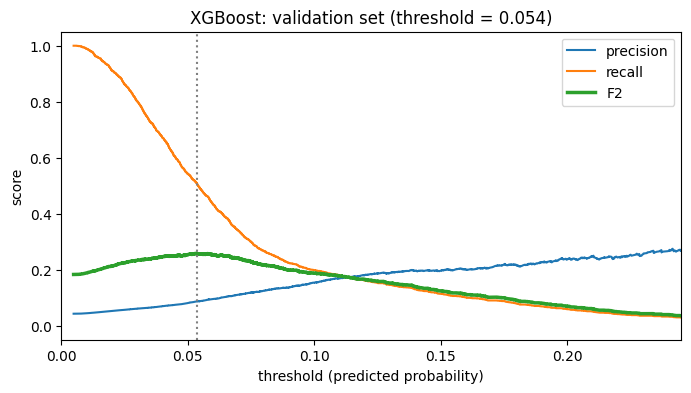

,threshold,validation F2
Logistic regression,0.0536,0.2525
Random forest,0.0527,0.2575
XGBoost,0.0535,0.2585


In [12]:
# ---- Find the F2-maximizing threshold on validation ----
def best_threshold(y_true, scores):
    prec, rec, thr = precision_recall_curve(y_true, scores)
    f2 = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
    i = np.argmax(f2[:-1])
    return thr[i], prec[:-1], rec[:-1], f2[:-1], thr

thresholds, val_f2 = {}, {}
for name, m in models.items():
    t, _, _, f2, _ = best_threshold(y_val, m.predict_proba(X_val)[:, 1])
    thresholds[name], val_f2[name] = t, f2.max()

# ---- Plot the curves for the best model ----
best = max(val_f2, key=val_f2.get)
t, prec, rec, f2, thr = best_threshold(y_val, models[best].predict_proba(X_val)[:, 1])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec, label="precision")
ax.plot(thr, rec, label="recall")
ax.plot(thr, f2, label="F2", lw=2.5)
ax.axvline(t, ls=":", color="gray")
ax.set_xlim(0, np.percentile(thr, 99.5))
ax.set(xlabel="threshold (predicted probability)", ylabel="score",
       title=f"{best}: validation set (threshold = {t:.3f})")
ax.legend()
plt.show()

pd.DataFrame({"threshold": thresholds, "validation F2": val_f2})

Every model picks a threshold near 0.053, which is close to the 4.29% positive rate rather
than the usual 0.5. That is what optimizing F2 on a rare outcome does: the model has to
flag a wide net to find enough positives, so the cutoff sits near the base rate.

Validation F2 runs from 0.253 to 0.259, with XGBoost highest. The precision, recall and F2
curves show why the choice is delicate. Recall falls steeply as the threshold rises while
precision barely improves, so moving the cutoff up trades away people reached for very
little gain in efficiency.

## 10. Test results

Each model is scored once on the test set at its validation threshold.

In [13]:
# ---- Score every model on the test set ----
rows = []
for name, m in models.items():
    s = m.predict_proba(X_test)[:, 1]
    pred = (s >= thresholds[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"model": name, "F2": fbeta_score(y_test, pred, beta=2),
                 "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
                 "AP": average_precision_score(y_test, s), "AUC": roc_auc_score(y_test, s),
                 "flagged %": 100 * pred.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "contacts per person reached": (tp + fp) / tp})

results = pd.DataFrame(rows).set_index("model").sort_values("F2", ascending=False)
print(f"Random contacting: {1 / y_test.mean():.1f} contacts per person reached")
results

Random contacting: 23.3 contacts per person reached


,F2,recall,precision,AP,AUC,flagged %,TP,FP,FN,TN,contacts per person reached
model,,,,,,,,,,,
Random forest,0.2551,0.5142,0.0846,0.1113,0.7002,26.0638,707,7648,668,23033,11.8175
XGBoost,0.2516,0.4945,0.0848,0.1132,0.7018,25.0031,680,7335,695,23346,11.7868
Logistic regression,0.2503,0.4553,0.0893,0.1057,0.6942,21.8586,626,6381,749,24300,11.1933


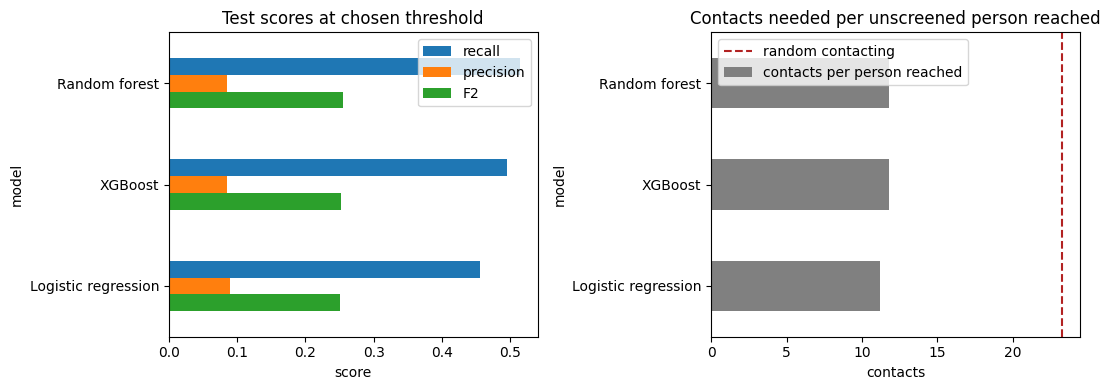

In [14]:
# ---- Plot recall vs. share contacted for each model ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

results[["recall", "precision", "F2"]].plot.barh(ax=axes[0])
axes[0].set(title="Test scores at chosen threshold", xlabel="score")
axes[0].invert_yaxis()

results["contacts per person reached"].plot.barh(ax=axes[1], color="gray")
axes[1].axvline(1 / y_test.mean(), ls="--", color="firebrick", label="random contacting")
axes[1].set(title="Contacts needed per unscreened person reached", xlabel="contacts")
axes[1].invert_yaxis()
axes[1].legend()

plt.tight_layout()
plt.show()

Random forest wins on test F2 at 0.255, with XGBoost at 0.252 and logistic regression at
0.250. The spread is about half a point of F2, which is narrower than the difference between
the validation and test scores for any single model, so the three are effectively tied.

The operational numbers are more informative than the ranking. Random forest reaches **707
of the 1,375 unscreened people in the test set, about 51%**, by contacting 26% of the group.
That works out to about **11.8 contacts per person reached, against 23.3 if you contacted
people at random** — roughly half the outreach effort for the same number found.

Precision is low by design. About 8.5% of the people flagged are actually unscreened, so
most contacts reach someone who already had a check. For a mailing or a phone campaign that
is an acceptable cost; for anything expensive or invasive it would not be.

These results sit close to the Task 2 figures in the Wolfgang Klein tab, which reports test
F2 of 0.257 for random forest from a much wider hyperparameter search over six model families
plus an ensemble. Cross-validated AP agrees to the third decimal on all three shared models.

Reaching 0.255 here with three models and small searches is the point of this tab. Two
independent builds landing within two thousandths of F2 says the ceiling on this task comes
from the data rather than from the tuning, so the team can report Wolfgang's numbers with
more confidence.

## 11. Summary

**The model works, but it is weak in absolute terms.** AUC near 0.70 and AP near 0.11 mean
the ranking carries real signal, and the 18 survey answers do separate people who skip
screening from people who do not. They do not separate them sharply.

**The practical value is in the ranking, not the classification.** Cutting outreach effort
roughly in half for the same number of people reached is useful for a screening program even
though any individual prediction is unreliable. That mirrors the Lab 1 conclusion that this
data supports risk ranking rather than individual classification.

**All three models agree, and so do the two independent builds.** Logistic regression, random
forest and XGBoost finish within half a point of F2 of each other. They also land within two
thousandths of the much larger search in the Wolfgang Klein tab. When a small search and a
tuned ensemble reach the same place, the limit is the information in the features.

**Use Wolfgang's tab for the reported numbers.** That notebook covers both tasks with the
wider search, so it is the team's primary result. This tab exists to show those numbers hold
up when the work is redone independently.

**Pairing the two tasks is the point.** Task 1 finds people whose profile looks like diabetes.
Task 2 finds people the health system is not reaching. The overlap between them, high-risk and
unscreened, is the group a screening program should contact first, and neither model identifies
it alone.

**What would improve this.** The strongest missing variables are geographic and structural:
distance to a clinic, local provider density, insurance type rather than the yes/no coverage
flag, and whether someone has a usual source of care. All of them sit outside this file.